# Token swaps across models with paired bootstrap intervals

**Question.** How stable are concept-swap success rates and J-minus-control gains
across source prompts, keeping replacement targets together?

**Answer/status.** The saved run is an executed offline demonstration: a tiny-model
mechanics check and explicitly synthetic result rows validate the pipeline. It is
not a pretrained-model result. Select `RUN_MODE="cache"` and point `CACHE_RUN_DIR`
at an existing token-swap run to analyze real results with no model/tokenizer
loading. Select `"pretrained"` for a new model experiment.

This version preserves the original audited tasks and primary setting: alpha=1
in the middle relative-depth band. It adds prompt-clustered confidence intervals,
paired J-minus-logit/J-minus-random differences, and a separate analysis manifest.
The original notebook and inference caches are not modified by cache analysis.


## Repository setup (local or Colab)

In a fresh Colab session, clone this GitHub fork; reuse an existing clone with
`git pull --ff-only` and install its dependencies into the active Python environment.
A notebook opened inside a local checkout uses that checkout directly. Clone, pull,
and installation errors stop the setup cell. Run this cell before importing `jlens`;
if you already imported an older version in this session, restart the runtime first.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/ai360-project-school-j-lens/jacobian-lens-gpt2.git"
IN_COLAB = "COLAB_RELEASE_TAG" in os.environ or "google.colab" in sys.modules

# Reuse a checkout when opened locally, including from a nested notebook folder.
local_repo = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "jlens" / "evaluation.py").is_file()),
    None,
)
REPO_DIR = local_repo or Path.cwd() / "jacobian-lens-gpt2"
if local_repo is not None:
    if IN_COLAB:
        subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=True)
elif REPO_DIR.exists():
    subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=True)
else:
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)

ROOT = REPO_DIR.resolve()
if IN_COLAB:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-e", str(ROOT)], check=True,
    )
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
if not (ROOT / "jlens" / "swap_experiment.py").is_file():
    raise RuntimeError("Update this checkout to the revision containing jlens/swap_experiment.py.")
print(f"Repository ready: {ROOT.name}")

Repository ready: jacobian-lens-gpt2


In [2]:
import json

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display

from jlens.swap_experiment import (
    experiment_fingerprint,
    intermediate_bands,
    load_swap_trials,
    prepare_swap_trials,
    run_swap_experiment,
)

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_columns", 20)
RUN_MODE = os.environ.get("JLENS_SWAP_MODE", "demo")  # "demo", "cache", or "pretrained"
CACHE_RUN_DIR = os.environ.get("JLENS_SWAP_CACHE", "")  # Folder containing results.json + manifest.json.
if RUN_MODE not in {"demo", "cache", "pretrained"}:
    raise ValueError("RUN_MODE must be demo, cache, or pretrained")
RUN_MODEL = RUN_MODE == "pretrained"
MODEL_ID = os.environ.get("JLENS_MODEL_ID", "Qwen/Qwen3-4B")
MODEL_REVISION = os.environ.get("JLENS_MODEL_REVISION", "main")  # Pin a commit for repeat runs.
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float32
EXISTING_LENS_PATH = os.environ.get("JLENS_LENS_PATH")  # Matching FINAL lens; never a checkpoint.
# Published J-lens files checked at the pinned Neuronpedia revision below.
HUB_LENS_FILES = {
    "Qwen/Qwen3-4B": "qwen3-4b/jlens/Salesforce-wikitext/Qwen3-4B_jacobian_lens.pt",
    "Qwen/Qwen3-1.7B": "qwen3-1.7b/jlens/Salesforce-wikitext/Qwen3-1.7B_jacobian_lens.pt",
    "openai-community/gpt2": "gpt2-small/jlens/Salesforce-wikitext/gpt2_jacobian_lens.pt",
    "google/gemma-4-31B": "gemma-4-31b/jlens/Salesforce-wikitext/gemma-4-31B_jacobian_lens.pt",
    "Qwen/Qwen3.5-9B-Base": "qwen3.5-9b-pt/jlens/Salesforce-wikitext/Qwen3.5-9B-Base_jacobian_lens.pt",
    "Qwen/Qwen3.5-4B": "qwen3.5-4b/jlens/Salesforce-wikitext/Qwen3.5-4B_jacobian_lens_n1000.pt",
}
HUB_LENS = (
    dict(repo_id="neuronpedia/jacobian-lens", filename=HUB_LENS_FILES[MODEL_ID],
         revision="9fa267f841d62aa468dab5b9b38c3dc45a82d863")
    if MODEL_ID in HUB_LENS_FILES and not EXISTING_LENS_PATH else None
)
# For another model, supply its exact artifact: dict(repo_id=..., filename=..., revision=...).
FIT_LENS = False  # Set True and HUB_LENS=None only to deliberately run/load a managed fit.
LENS_PROVENANCE = None
lens = None
BATCH_SIZE = 16
ALPHAS = [0.0, 1.0, 2.0]
SEED = 0
MAX_PROMPT_LENGTH = 256
RUN_ROOT = ROOT / "runs/model-agnostic-token-swap"
results = prepared = None
print(f"Pretrained experiment enabled: {RUN_MODEL}; device: {DEVICE}")

Pretrained experiment enabled: False; device: cpu


In [3]:
from jlens.bootstrap import swap_bootstrap

BOOTSTRAP_OPTIONS = dict(
    n_resamples=int(os.environ.get("JLENS_BOOTSTRAP_RESAMPLES", "10000")),
    confidence=0.95, seed=0, batch_size=256,
)

## Dataset provenance and quality

The local `probe-swap.json` and `flexible-generalization.json` were verified **byte-for-byte** against [Anthropic's upstream release at commit 581d398](https://github.com/anthropics/jacobian-lens/tree/581d398613e5602a5af361e1c34d3a92ea82ba8e/data/experiments). Their hashes and the review decisions are in `data/experiments/token-swap-audit.json`; the original data are unchanged. The [paper](https://transformer-circuits.pub/2026/workspace/index.html) motivates bandwise coordinate interventions; this notebook is an adaptation, not an exact replication of its model or scores.

The review found incomplete answer labels (e.g. `North`, `Canadian`, `Civil`, and square answers `twenty`/`forty`/`eighty`), underspecified relations, and counterfactuals that violate the question's answer type. The China population premise is outdated: see [UN DESA's 2023 population brief](https://www.un.org/development/desa/pd/content/policy-brief153). Exclusions are conservative review decisions, not an exhaustive certification that every retained fact and alternative wording is correct.

Local v1 has 400 trials from **100 landmark prompts**, each with four replacement countries. It is useful as a narrow supplementary country→language task, with repeated prompts and simplified language labels. Remove ambiguous transboundary/disputed landmarks and India language trials conservatively. V2 has 1,416 trials from 354 subjects selected on GPT-2 XL answers; its 100% construction baseline does not transfer to other models. The default uses v1 instead. Explicit-source flexible tasks and latent-source two-hop tasks must not be pooled.

In [4]:
audit = json.loads((ROOT / "data/experiments/token-swap-audit.json").read_text())
trials = load_swap_trials(ROOT)
quality_summary = trials.groupby("dataset").agg(
    raw_trials=("name", "size"), raw_prompts=("prompt", "nunique"),
    retained_trials=("quality_ok", "sum"),
)
quality_summary["retained_prompts"] = trials[trials.quality_ok].groupby("dataset").prompt.nunique()
display(quality_summary)
display(trials[~trials.quality_ok].groupby(["dataset", "quality_reason"]).size().rename("excluded_trials").to_frame())
print(audit["latent_v2"])
for limitation in audit["limitations"]:
    print("•", limitation)

,raw_trials,raw_prompts,retained_trials,retained_prompts
dataset,,,,
flexible-generalization,192,64,144,48
latent-bridge,400,100,344,91
probe-swap,90,86,71,68


excluded_trials
dataset                 quality_reason                                                                                                       
flexible-generalization Biggest holiday is culture-dependent, Easter moves, and labels are fragments.                                      12
                        North is an incomplete answer for North America; exclude the whole relation for balanced coverage.                 12
                        Sky/outdoors do not specify a unique natural habitat.                                                              12
                        twenty, forty and eighty are only prefixes of 25, 49 and 81.                                                       12
latent-bridge           Country attribution in East Jerusalem is disputed.                                                                  8
                        One canonical main-language label hides substantial linguistic diversity; excluded conservatively.                 40
                        Transboundary landmark does not identify a unique country.                                                          4
                        Transboundary landmark does not identify a unique country.; One canonical main-language label hid...                4
probe-swap              At least one label is only a prefix of a multi-word answer.                                                         7
                        Belgium has more than one western neighbor; direction is underspecified.                                            1
                        Colors depend on species; the eagle label is underspecified.                                                        1
                        Easter does not have a fixed month.                                                                                 1
                        Lung lobes are not heart chambers; the counterfactual changes relation.                                             1
                        Outdated China premise; India overtook China in 2023.                                                               1
                        Seasons require a hemisphere; none is specified.                                                                    1
                        The counterfactual asks for a fruit, but barley is a cereal.                                                        1
                        The counterfactual asks for an animal but labels earth.                                                             1
                        The counterfactual asks for an insect but labels a cow.                                                             1
                        The counterfactual rider's power source is ill-formed for a train.                                                  1
                        The swan-to-England national-emblem relation is not well defined.                                                   1
                        Wooden objects used to strike an instrument do not describe piano keys.                                             1

Excluded from default experiments: 1416 rows are four targets for 354 subjects preselected for GPT-2 XL capability. Use v1 for cross-model coverage; v2 requires a separately reported model-specific analysis.
• Latent bridge v1 has one country-to-language relation, 100 source landmarks and four targets per prompt, not 400 independent questions.
• Country/language labels simplify multilingual countries; retained labels are canonical continuations, not exhaustive accepted answers.
• Single-token scoring undercounts valid synonyms, number forms and multi-token answers; report coverage for each tokenizer.
• Anthropic flexible tasks explicitly mention the source; report separately from hidden intermediate tasks.
• Do not select the best band on the same prompts and call its score held-out performance.


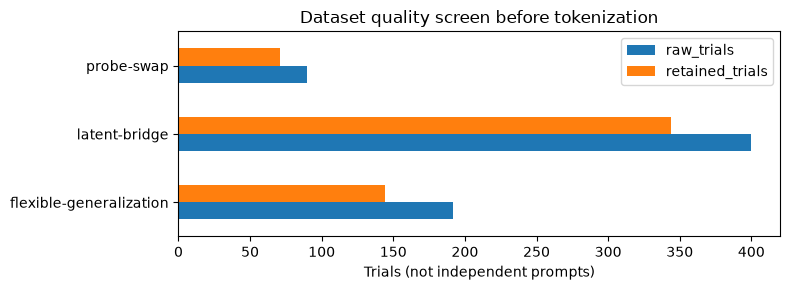

In [5]:
fig, ax = plt.subplots(figsize=(8, 3))
quality_summary[["raw_trials", "retained_trials"]].plot.barh(ax=ax)
ax.set(xlabel="Trials (not independent prompts)", ylabel="", title="Dataset quality screen before tokenization")
plt.tight_layout()
plt.show()

## Intervention and scoring

For source and replacement token directions at layer ℓ, form `V = [v_source, v_target]`. Compute clean coordinates `c_clean = V⁺ h_clean`. After each selected block, set

`h_patched ← h_patched + V[c_clean + α(swap(c_clean) − c_clean) − V⁺h_patched]`.

At α=1, the two clean coordinates exchange; the orthogonal component is preserved. Clamping to clean coordinates avoids undoing the swap on alternate layers. `α=0` is an exact no-op. The J directions are `Jᵀ C(gain × unembedding)` for LayerNorm and `Jᵀ(gain × unembedding)` for RMSNorm. Effective norm gain includes offset parameterizations such as Gemma's `1 + weight`.

Three arms run over the same prompts: J-space swap; logit-direction swap without J; and a random update matched **at each layer and position to the actual J arm's update norm**. The random seed is fixed; random draws depend on batching, which is recorded. α=2 and the band sweep are exploratory. The predeclared primary setting is **α=1, middle of the three depth bands**. Do not report the best observed setting as held-out performance.

Prompts use the adapter's normal special-token policy, without a chat wrapper or silent truncation. A concept must have a complete, exact single-token spelling (space-prefixed first, otherwise bare). Answers use complete single-token case/space variants only; no first-token fallback. Both answer sets must be nonempty and disjoint. Multi-token words are excluded and counted, not silently replaced by their first token.

Prompts are length-grouped and batched; compatible adapters use right padding and attention masks. Other adapters use equal-length batches. All real non-special prompt positions are patched. BOS, EOS and padding are untouched. The final distribution is obtained from the last block at each row's last real token through `model.unembed`, including the model's final normalization and logit transforms.

Report baseline accuracy over eligible data, then target flips conditional on a unique correct baseline top token. Also show any-output-change rate and target-probability gain. Tied top scores are not accepted as capability or success. Ranks use competition ranks and are descriptive. Multiple targets for one prompt are correlated: summary rates first average within each prompt, then across prompts. Intervals below resample source prompts, never individual target trials.

## Executed CPU smoke check

This random, untrained decoder only checks the intervention mechanics. Its output changes do **not** demonstrate factual concept transfer. Regression tests additionally check distinct per-row coordinates, padding, exact no-ops, random norm matching, token rejection, normalization, and hook cleanup.

In [6]:
if RUN_MODE == "demo":
    from jlens import JacobianLens
    from tests.tiny import TinyDecoder

    smoke_model = TinyDecoder().eval()
    smoke_lens = JacobianLens(
        {layer: torch.eye(smoke_model.d_model) for layer in range(smoke_model.n_layers)},
        n_prompts=1, d_model=smoke_model.d_model,
    )
    smoke_trials = pd.DataFrame([
        dict(trial_id=str(i), dataset="synthetic", group="smoke", name=str(i),
             prompt=str(i), source="a", target="b", answer="c", swap_answer="d",
             input_ids=ids, source_id=source, target_id=target,
             answer_ids=[4, 5], swap_answer_ids=[6, 7], eligible=True)
        for i, (ids, source, target) in enumerate([
            ([0, 1, 2, 3], 3, 9), ([0, 2, 3], 4, 10), ([0, 5, 6, 7], 5, 11),
        ])
    ])
    smoke = run_swap_experiment(
        smoke_model, smoke_lens, smoke_trials, bands={"middle": [1, 2]},
        alphas=[0.0, 1.0], batch_size=3, seed=SEED, progress=False,
    )
    assert not smoke[smoke.alpha.eq(0)].changed.any()
    display(smoke.groupby(["mode", "alpha"]).agg(trials=("name", "size"), changed=("changed", "sum")))
    print("CPU smoke passed: all zero-strength arms preserve the final top token.")
else:
    print("Skipping the optional tiny-model mechanics check.")

trials  changed
mode   alpha                 
J      0.0         3        0
       1.0         3        2
logit  0.0         3        0
       1.0         3        2
random 0.0         3        0
       1.0         3        1

CPU smoke passed: all zero-strength arms preserve the final top token.


## Choose an existing cache or run a model

`RUN_MODE="cache"`: set `CACHE_RUN_DIR` to a folder containing the original
`results.json` and `manifest.json`. The model identity and band definitions come
from that manifest; the current model defaults are ignored. This path loads no
model, lens, or tokenizer and makes no Hub requests. Missing files are errors;
there is no fallback to inference. Keep the original cache and manifest together.

`RUN_MODE="pretrained"`: configure model, dtype, and matching lens as in the
original token-swap notebook. Results use the original inference cache. The
bootstrap settings do not enter that cache key.

`RUN_MODE="demo"`: use synthetic result rows to demonstrate intervals and paired
contrasts offline. All resulting figures and exports are labeled synthetic.


In [7]:
lens = None  # A failed load must not leave an earlier lens available.
results = prepared = None
LENS_PROVENANCE = None
if RUN_MODEL:
    if sum([HUB_LENS is not None, bool(EXISTING_LENS_PATH), FIT_LENS]) != 1:
        raise ValueError("Choose one lens source: HUB_LENS, EXISTING_LENS_PATH, or FIT_LENS=True.")
    import hashlib

    import transformers
    from transformers import AutoModelForCausalLM, AutoTokenizer

    import jlens
    from jlens.artifact_provenance import download_lens_artifact
    from jlens.evaluation import FIT_MIX, fit_with_progress, load_fit_prompts
    from jlens.notebook_setup import DatasetFitRun, runtime_metadata
    from jlens.sharded_fitting import benchmark_dim_batches

    torch.manual_seed(SEED)
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
    hf_model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID, revision=MODEL_REVISION, dtype=DTYPE,
    ).to(DEVICE).eval()
    model = jlens.from_hf(hf_model, tokenizer, compile=False)
    RUNTIME = runtime_metadata(model, hf_model, MODEL_ID, DTYPE, DEVICE)
    FIT_CONFIG = {
        **RUNTIME,
        "max_seq_len": 128, "skip_first": 16,
        "fit_mix": {key: max(1, round(count * 0.25)) for key, count in FIT_MIX.items()},
        "seed": SEED, "run_label": "token-swap-v1", "checkpoint_every": 5,
        "dim_batch_requested": 8, "candidates": [4, 8, 16, 32],
        "headroom_fraction": 0.15, "headroom_GiB": 2.0,
    }
    fit_run = DatasetFitRun(RUN_ROOT / "fits", FIT_CONFIG)
    selected_path = EXISTING_LENS_PATH
    if HUB_LENS is not None:
        artifact = download_lens_artifact(**HUB_LENS)
        selected_path = artifact.path
        LENS_PROVENANCE = {**artifact.to_dict(), "evaluation_runtime": RUNTIME}
        display(LENS_PROVENANCE)
    lens = fit_run.load_or_fit(
        model, FIT_CONFIG, load_prompts=load_fit_prompts,
        fit=fit_with_progress, benchmark=benchmark_dim_batches,
        display=display, existing_path=selected_path,
    )
    LENS_PATH = str(selected_path or fit_run.lens_path)
    LENS_SOURCE = "hub" if HUB_LENS is not None else "local" if selected_path else "managed"
    BANDS = intermediate_bands(model.n_layers)
    PRIMARY_BAND = list(BANDS)[len(BANDS) // 2]
    prepared = prepare_swap_trials(model, trials, max_length=MAX_PROMPT_LENGTH)
    display(prepared.groupby("dataset").agg(
        raw=("name", "size"), quality_ok=("quality_ok", "sum"),
        token_ok=("token_ok", "sum"), eligible=("eligible", "sum"),
    ))
    display(prepared[~prepared.token_ok].groupby(["dataset", "token_reason"]).size().rename("trials").to_frame())
    print("Primary band:", PRIMARY_BAND, "; all bands:", BANDS)
elif RUN_MODE == "cache":
    if not CACHE_RUN_DIR:
        raise ValueError("Set CACHE_RUN_DIR to the existing token-swap result folder")
    source_dir = Path(CACHE_RUN_DIR).expanduser().resolve()
    metadata = json.loads((source_dir / "manifest.json").read_text())
    result_path = source_dir / "results.json"
    results = pd.DataFrame(json.loads(result_path.read_text()))
    BANDS = metadata["bands"]
    if not BANDS or not all(BANDS.values()):
        raise ValueError("Source manifest must record nonempty intervention bands")
    band_order = sorted(BANDS, key=lambda name: min(BANDS[name]))
    PRIMARY_BAND = band_order[len(band_order) // 2]
    if set(results.band) != set(BANDS) or set(results.alpha) != set(metadata["alphas"]):
        raise ValueError("Result settings differ from the source manifest")
    print("Cache-only model:", metadata.get("model_id"), "; primary band:", PRIMARY_BAND)
    display(metadata)
else:
    # Explicitly synthetic outcomes; no scientific model claim.
    BANDS = {"early": [0], "middle": [1], "late": [2]}
    PRIMARY_BAND = "middle"
    metadata = {"model_id": "offline/synthetic-swap-demo", "mode": "demo", "bands": BANDS,
                "alphas": ALPHAS, "seed": SEED}
    results = pd.DataFrame([
        dict(dataset="synthetic", band=band, alpha=alpha, trial_id=f"{prompt}-{target}",
             name=f"{prompt}-{target}", prompt=f"Synthetic prompt {prompt}",
             source="source", target=str(target), answer="clean", swap_answer="replacement",
             baseline_text="clean", patched_text="replacement" if hit else "clean",
             mode=arm, base_correct=prompt < 10, success=hit, changed=hit,
             base_probability=0.01, probability=0.8 if hit else 0.01)
        for band in BANDS for alpha in ALPHAS for prompt in range(12) for target in range(4)
        for arm in ["J", "logit", "random"]
        for hit in [bool(alpha and ((prompt + target) % 7 < (4 if arm == "J" else 1 if arm == "logit" else 0)))]
    ])
    result_path = None
    print("Synthetic demonstration; these are not trained-model measurements.")


Synthetic demonstration; these are not trained-model measurements.


In [8]:
if RUN_MODEL:
    if lens is None:
        raise RuntimeError("Load the selected lens successfully before running swaps.")
    metadata = {
        **(FIT_CONFIG if LENS_SOURCE == "managed" else RUNTIME),
        "model_revision_requested": MODEL_REVISION,
        "model_revision_resolved": getattr(hf_model.config, "_commit_hash", None),
        "tokenizer_sha256": hashlib.sha256(json.dumps(tokenizer.get_vocab(), sort_keys=True).encode()).hexdigest(),
        "torch_version": torch.__version__, "transformers_version": transformers.__version__,
        "bands": BANDS, "alphas": ALPHAS, "batch_size": BATCH_SIZE,
        "max_prompt_length": MAX_PROMPT_LENGTH, "seed": SEED,
        "lens_n_prompts": lens.n_prompts,
        "lens_origin": LENS_PATH, "lens_source": LENS_SOURCE,
        "lens_artifact": LENS_PROVENANCE,
        "fit_provenance": "managed independent corpus" if LENS_SOURCE == "managed" else "unverified existing artifact",
    }
    key = experiment_fingerprint(metadata, prepared, lens)
    run_dir = RUN_ROOT / key
    run_dir.mkdir(parents=True, exist_ok=True)
    if LENS_PROVENANCE is not None:
        (run_dir / "downloaded_lens_provenance.json").write_text(json.dumps(LENS_PROVENANCE, indent=2))
    result_path = run_dir / "results.json"
    prepared.to_json(run_dir / "trial_audit.json", orient="records", indent=2)
    (run_dir / "manifest.json").write_text(json.dumps(metadata, indent=2))
    if result_path.exists():
        results = pd.DataFrame(json.loads(result_path.read_text()))
        print("Loaded cached model passes:", result_path)
    else:
        results = run_swap_experiment(
            model, lens, prepared, bands=BANDS, alphas=ALPHAS,
            batch_size=BATCH_SIZE, seed=SEED,
        )
        temporary = result_path.with_suffix(".tmp.json")
        results.to_json(temporary, orient="records", indent=2, double_precision=15)
        temporary.replace(result_path)
    print("Completed result rows:", len(results))
else:
    print("Using the results selected above; no pretrained inference.")

Using the results selected above; no pretrained inference.


## Results: coverage, capability, and causal effects

Baseline accuracy is recomputed independently for the selected model. Excluding incorrect baselines is a capability condition, not evidence that the entire raw dataset is solvable. Compare coverage and baseline accuracy before comparing models' conditional swap rates. Retain the per-trial audit and report the intersection of eligible prompts for stricter cross-model comparisons.

In [9]:
summary = primary = None
if results is not None and not results.empty:
    baseline = results.drop_duplicates("trial_id")
    display(baseline.groupby("dataset").agg(
        eligible_trials=("name", "size"), eligible_prompts=("prompt", "nunique"),
        baseline_correct_trials=("base_correct", "sum"),
    ))
    display(baseline.drop_duplicates(["dataset", "prompt"]).groupby("dataset").base_correct.agg(["mean", "size"]))
    correct = results[results.base_correct].copy()
    correct["probability_gain"] = correct.probability - correct.base_probability
    keys = ["dataset", "mode", "band", "alpha"]
    if not correct.empty:
        per_prompt = correct.groupby(keys + ["prompt"])[["success", "changed", "probability_gain"]].mean()
        summary = per_prompt.groupby(keys).agg(
            target_flip=("success", "mean"), any_change=("changed", "mean"),
            probability_gain=("probability_gain", "mean"), prompts=("success", "size"),
        ).reset_index()
        primary = summary[summary.band.eq(PRIMARY_BAND) & summary.alpha.eq(1)]
        display(primary)
        display(summary)
        display(correct[correct['mode'].eq("J") & correct.band.eq(PRIMARY_BAND) & correct.alpha.eq(1)].groupby("dataset").head(8)[
            ["dataset", "prompt", "source", "target", "baseline_text", "patched_text", "swap_answer", "success"]
        ])
    else:
        print("No eligible prompt has a unique correct baseline answer; causal success is undefined.")
else:
    print("No pretrained results available; no success rates to report.")

,eligible_trials,eligible_prompts,baseline_correct_trials
dataset,,,
synthetic,48,12,40


,mean,size
dataset,,
synthetic,0.833333,12


,dataset,mode,band,alpha,target_flip,any_change,probability_gain,prompts
7,synthetic,J,middle,1.0,0.625,0.625,0.49375,10
16,synthetic,logit,middle,1.0,0.125,0.125,0.09875,10
25,synthetic,random,middle,1.0,0.000,0.000,0.00000,10


,dataset,mode,band,alpha,target_flip,any_change,probability_gain,prompts
0,synthetic,J,early,0.0,0.000,0.000,0.00000,10
1,synthetic,J,early,1.0,0.625,0.625,0.49375,10
2,synthetic,J,early,2.0,0.625,0.625,0.49375,10
3,synthetic,J,late,0.0,0.000,0.000,0.00000,10
4,synthetic,J,late,1.0,0.625,0.625,0.49375,10
5,synthetic,J,late,2.0,0.625,0.625,0.49375,10
6,synthetic,J,middle,0.0,0.000,0.000,0.00000,10
7,synthetic,J,middle,1.0,0.625,0.625,0.49375,10
8,synthetic,J,middle,2.0,0.625,0.625,0.49375,10
9,synthetic,logit,early,0.0,0.000,0.000,0.00000,10


,dataset,prompt,source,target,baseline_text,patched_text,swap_answer,success
576,synthetic,Synthetic prompt 0,source,0,clean,replacement,replacement,True
579,synthetic,Synthetic prompt 0,source,1,clean,replacement,replacement,True
582,synthetic,Synthetic prompt 0,source,2,clean,replacement,replacement,True
585,synthetic,Synthetic prompt 0,source,3,clean,replacement,replacement,True
588,synthetic,Synthetic prompt 1,source,0,clean,replacement,replacement,True
591,synthetic,Synthetic prompt 1,source,1,clean,replacement,replacement,True
594,synthetic,Synthetic prompt 1,source,2,clean,replacement,replacement,True
597,synthetic,Synthetic prompt 1,source,3,clean,clean,replacement,False


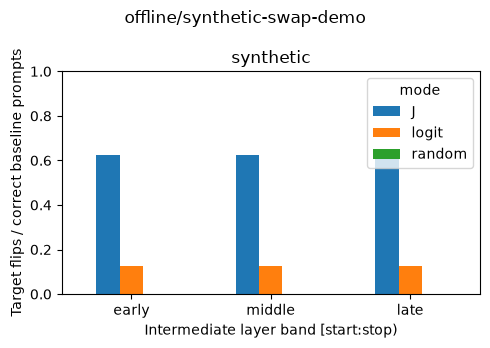

In [10]:
if summary is not None and not summary.empty:
    selected = summary[summary.alpha.eq(1)]
    datasets = list(selected.dataset.unique())
    fig, axes = plt.subplots(1, len(datasets), figsize=(5 * len(datasets), 3.5), squeeze=False)
    for ax, dataset in zip(axes[0], datasets, strict=True):
        table = selected[selected.dataset.eq(dataset)].pivot(index="band", columns="mode", values="target_flip")
        table.reindex(list(BANDS)).plot.bar(ax=ax, ylim=(0, 1), rot=0)
        ax.set(title=dataset, ylabel="Target flips / correct baseline prompts", xlabel="Intermediate layer band [start:stop)")
    fig.suptitle(metadata.get("model_id", "cached model"))
    plt.tight_layout()
    plt.show()

## Paired bootstrap: what the intervals measure

These are **pointwise percentile intervals (95% by default)** for a fixed model, lens, scoring
rule, and setting. Resample complete prompt clusters with replacement, using the
same draws for every method and computing the method difference on each draw.
The original point estimate remains unchanged. No model passes or lens refits
are needed to change the bootstrap seed, confidence level, or resample count.

`status="ok"` means an interval was estimated. `degenerate` means the observed
bootstrap distribution is constant; its interval is deliberately left null.
In particular, 0 observed successes is **not** a demonstrated population rate
of zero. `too_few_clusters` and `no_supported_units` also have null intervals.
Coverage counts distinguish absent support from failed retrieval. No bootstrap
upper bound is inferred for an all-zero control.

Intervals assume the chosen clusters are independent and represent similar
benchmark examples. They do not cover new task families, lens fitting
variability, random-control seeds, or model nondeterminism. They do not correct
selection of the best setting on these data or simultaneous testing of many
datasets/settings. Primary settings stay fixed; sweeps are exploratory.

Replacement targets stay together within their source prompt. Baseline filtering is shared across arms. The intervals are conditional on a correct baseline; they are not unconditional task-success intervals.

In [11]:
import hashlib

ci_table = swap_bootstrap(results, **BOOTSTRAP_OPTIONS)
ci_table["analysis_role"] = "exploratory"
ci_table.loc[ci_table.band.eq(PRIMARY_BAND) & ci_table.alpha.eq(1), "analysis_role"] = "primary"
primary_ci = ci_table[ci_table.analysis_role.eq("primary") & ci_table.metric.eq("success")]
display(primary_ci[["dataset", "statistic", "arm", "reference", "estimate", "ci_low", "ci_high",
                    "status", "n_units", "n_clusters", "n_trials"]].round(4))

# Verify the bootstrap retains the original equal-prompt point estimates.
if summary is not None and not summary.empty:
    check = ci_table[ci_table.statistic.eq("arm") & ci_table.metric.eq("success")].merge(
        summary, left_on=["dataset", "arm", "band", "alpha"],
        right_on=["dataset", "mode", "band", "alpha"], validate="one_to_one",
    )
    assert len(check) == len(summary)
    assert (check.estimate - check.target_flip).abs().lt(1e-12).all()
else:
    assert ci_table.status.eq("no_supported_units").all()

source_bytes = result_path.read_bytes() if result_path is not None else results.to_json().encode()
analysis_manifest = {
    "schema": 1, "run_mode": RUN_MODE, "source_manifest": metadata,
    "source_results_sha256": hashlib.sha256(source_bytes).hexdigest(),
    "bootstrap": BOOTSTRAP_OPTIONS, "primary_band": PRIMARY_BAND, "primary_alpha": 1,
    "implementation_sha256": hashlib.sha256((ROOT / "jlens/bootstrap.py").read_bytes()).hexdigest(),
    "notebook_code_sha256": hashlib.sha256(json.dumps([
        "".join(c["source"]) for c in json.loads((ROOT / "notebooks/model_agnostic/token_swap/model_agnostic_token_swap_bootstrap.ipynb").read_text())["cells"]
        if c["cell_type"] == "code"
    ]).encode()).hexdigest(),
}
analysis_key = hashlib.sha256(json.dumps(analysis_manifest, sort_keys=True).encode()).hexdigest()[:20]
ANALYSIS_DIR = ROOT / "runs/bootstrap-token-swap" / analysis_key
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
(ANALYSIS_DIR / "manifest.json").write_text(json.dumps(analysis_manifest, indent=2) + "\n")
ci_table.to_csv(ANALYSIS_DIR / "bootstrap_intervals.csv", index=False)
primary_ci.to_csv(ANALYSIS_DIR / "primary_intervals.csv", index=False)
print("Analysis exports:", ANALYSIS_DIR)

,dataset,statistic,arm,reference,estimate,ci_low,ci_high,status,n_units,n_clusters,n_trials
105,synthetic,arm,J,,0.625,0.475,0.775,ok,10,10,40
106,synthetic,arm,logit,,0.125,0.050,0.200,ok,10,10,40
107,synthetic,arm,random,,0.000,NaN,NaN,degenerate,10,10,40
108,synthetic,difference,J,logit,0.500,0.350,0.650,ok,10,10,40
109,synthetic,difference,J,random,0.625,0.475,0.775,ok,10,10,40


Analysis exports: /home/kitlix/projects/jacobian-lens-gpt2/runs/bootstrap-token-swap/96d2105ed5742eaf7fbb


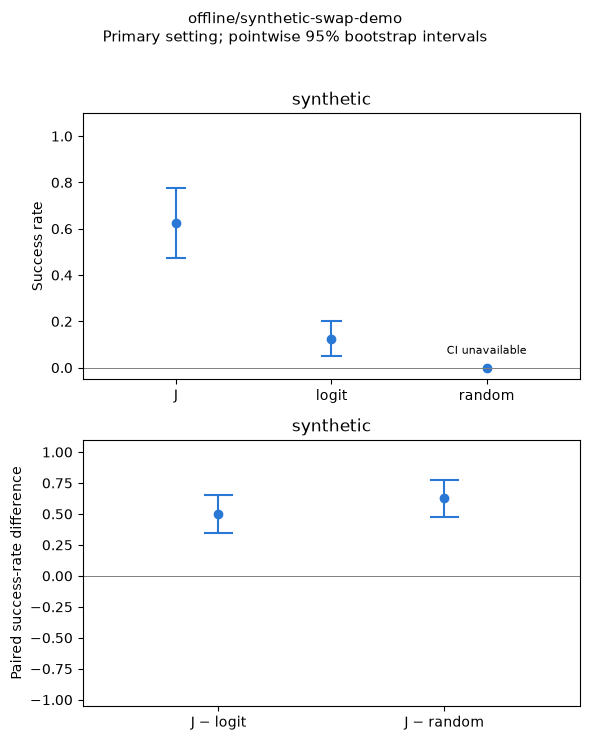

In [12]:
datasets = list(primary_ci.dataset.unique())
fig, axes = plt.subplots(2, len(datasets), figsize=(max(6, 5 * len(datasets)), 7.5), squeeze=False)
for column, dataset in enumerate(datasets):
    for row, statistic in enumerate(["arm", "difference"]):
        table = primary_ci[primary_ci.dataset.eq(dataset) & primary_ci.statistic.eq(statistic)]
        ax = axes[row, column]
        for x, value in enumerate(table.itertuples()):
            if pd.isna(value.estimate):
                ax.text(x, .5, "No supported prompts", transform=ax.get_xaxis_transform(),
                        ha="center", rotation=90, fontsize=8)
                continue
            ax.scatter(x, value.estimate, color="#2a78d6")
            if value.status == "ok":
                ax.vlines(x, value.ci_low, value.ci_high, color="#2a78d6")
                ax.plot([x - .06, x + .06], [value.ci_low] * 2, color="#2a78d6")
                ax.plot([x - .06, x + .06], [value.ci_high] * 2, color="#2a78d6")
            else:
                ax.annotate("CI unavailable", (x, value.estimate), xytext=(0, 10),
                            textcoords="offset points", ha="center", fontsize=8)
        labels = [r.arm if statistic == "arm" else f"{r.arm} − {r.reference}" for r in table.itertuples()]
        ax.set_xticks(range(len(table)), labels)
        ax.set_xlim(-.6, len(table) - .4)
        ax.set(title=dataset, ylabel="Success rate" if row == 0 else "Paired success-rate difference")
        ax.axhline(0, color="gray", linewidth=.7)
        ax.set_ylim((-.05, 1.1) if row == 0 else (-1.05, 1.1))
fig.suptitle(f"{metadata.get('model_id')}\nPrimary setting; pointwise "
             f"{100 * BOOTSTRAP_OPTIONS['confidence']:g}% bootstrap intervals", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, .96))
fig.savefig(ANALYSIS_DIR / "primary_bootstrap.png", dpi=160)
fig.savefig(ANALYSIS_DIR / "primary_bootstrap.svg")
plt.show()

## Conclusions

The original Anthropic datasets are already present and authentic, but authenticity does not make every label suitable for strict whole-answer scoring. The audited versions and local latent-bridge v1 are useful complementary diagnostics. V1 measures only country→language transfer; v2's GPT-2 XL preselection makes it unsuitable as the default cross-model dataset.

A J-space intervention supports specific conceptual transfer when the correct target answer becomes top-1 more often than under random perturbations, with the baseline originally correct. A large any-change rate alone can reflect disruption. Logit-direction controls show whether J adds value. Use the primary setting for the headline and the full band/strength grid for exploration. Single-token coverage, alternate valid answers, correlated targets, and limited relation diversity remain limitations.

In [13]:
print("Source:", metadata.get("model_id", "cached model"))
if primary is None or primary.empty:
    print("Current empirical conclusion: data audit and CPU mechanics only. Pretrained causal effects remain unmeasured.")
else:
    for dataset in primary.dataset.unique():
        frame = primary[primary.dataset.eq(dataset)].set_index("mode")
        print(f"{dataset}, primary band {PRIMARY_BAND}, α=1: " + "; ".join(
            f"{mode} target flips {row.target_flip:.1%}, any change {row.any_change:.1%}, n={int(row.prompts)} prompts"
            for mode, row in frame.iterrows()
        ))

Source: offline/synthetic-swap-demo
synthetic, primary band middle, α=1: J target flips 62.5%, any change 62.5%, n=10 prompts; logit target flips 12.5%, any change 12.5%, n=10 prompts; random target flips 0.0%, any change 0.0%, n=10 prompts


## Conclusions of this version

The saved synthetic demonstration checks nontrivial paired gains and unavailable
intervals for constant random controls. It supplies no trained-model success rate.
For a cached model run, use the **primary** interval table and its prompt counts;
the other settings remain exploratory. A null CI must be explained by `status`,
not drawn as a zero-width error bar. Keep baseline capability, coverage, source
manifest, and bootstrap manifest with exported figures. Comparing different
models additionally requires comparable eligible prompts and task protocols.